## Part 3: Combine SATCAT and ELSET data
#### 1. Combine the content of the 'DS_decayedLEODebris.csv' and 'DS_OMMs.csv' based on the Norad ID

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# read data SATCAT data from csv
decayedLEODebris_df = pd.read_csv('../Data/DS_decayedLEODebris.csv')
decayedLEODebris_df.head()

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,APOGEE,PERIGEE,RCS_SIZE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN
2,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN
3,1960-003C,33,DEBRIS,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,93.59,51.29,615.0,285.0,NaN
4,1960-005B,35,ROCKET BODY,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,88.48,64.89,199.0,199.0,NaN


In [62]:
# read ELSET data from csv
OMMs_df = pd.read_csv('../Data/DS_OMMs.csv')
OMMs_df.head()

,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,NORAD_CAT_ID,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,APOAPSIS,PERIAPSIS,OBJECT_TYPE,RCS_SIZE,LAUNCH_DATE,SITE,DECAY_DATE
0,THOR ABLESTAR R/B,1960-003A,1961-08-16T14:24:53.774496,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,30,7590,0.0,0.021256,0.0,6572.405,88.378,194.270,194.270,ROCKET BODY,NaN,NaN,NaN,1961-08-18
1,THOR ABLESTAR DEB,1960-003C,1960-10-06T07:59:06.496512,15.383434,0.024276,51.2879,136.0668,196.7800,163.6100,33,2700,0.0,0.000019,0.0,6829.149,93.607,616.796,285.231,DEBRIS,NaN,NaN,NaN,1960-07-17
2,SL-3 R/B,1960-005B,1960-07-16T04:00:11.150208,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,35,990,0.0,0.032711,0.0,6577.344,88.477,199.209,199.209,ROCKET BODY,NaN,NaN,NaN,1960-07-17
3,SPUTNIK 4 DEB,1960-005D,1961-03-15T15:48:42.802271,15.498003,0.019840,64.8899,343.2411,333.4201,27.0840,37,4690,0.0,0.000390,0.0,6795.450,92.915,552.139,282.492,DEBRIS,NaN,NaN,NaN,1961-06-30
4,SPUTNIK 4 DEB,1960-005E,1960-08-19T16:34:33.722976,15.889090,0.003421,64.8899,302.1218,49.4823,310.6691,38,1500,0.0,0.006108,0.0,6683.481,90.628,328.212,282.480,DEBRIS,NaN,NaN,NaN,1960-08-20


In [37]:
# merge the two dataframes with outer join
combined_df = pd.merge(decayedLEODebris_df, OMMs_df, on='NORAD_CAT_ID', how='outer')
combined_df.head()

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,89.24,50.27,249.0,225.0,MEDIUM,JUNO II R/B,1959-009B,1989-07-14T18:51:46.968192,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,58050.0,0.003007,0.027318,0.019637,6615.232,89.243,249.232,224.963,ROCKET BODY,MEDIUM,1959-10-13,AFETR,1989-07-16
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,87.80,48.34,168.0,163.0,LARGE,THOR ABLE R/B,1960-002A,1991-07-02T11:34:12.753984,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,67681.0,0.001474,0.208109,0.000057,6543.639,87.798,167.878,163.130,ROCKET BODY,LARGE,1960-04-01,AFETR,1991-07-03
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN,THOR ABLESTAR R/B,1960-003A,1961-08-16T14:24:53.774496,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,7590.0,0.000000,0.021256,0.000000,6572.405,88.378,194.270,194.270,ROCKET BODY,NaN,NaN,NaN,1961-08-18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25715,2024-221C,62113,ROCKET BODY,ZQ-2E R/B,PRC,2024-11-27,JSC,2024-12-24,87.60,49.89,184.0,127.0,LARGE,ZQ-2E R/B,2024-221C,2024-12-24T06:33:51.112800,16.438900,0.004298,49.8914,275.2215,178.2700,320.2910,429.0,0.000232,0.170634,0.000012,6533.612,87.597,183.558,127.396,ROCKET BODY,LARGE,2024-11-27,JSC,2024-12-24
25716,2024-228B,62191,ROCKET BODY,KZ-1A R/B,PRC,2024-12-04,XSC,2024-12-05,88.60,46.09,294.0,116.0,LARGE,KZ-1A R/B,2024-228B,2024-12-05T12:05:44.031840,16.253371,0.013499,46.0912,100.6897,6.8812,42.8048,13.0,0.000480,0.338528,0.000013,6583.238,88.597,293.973,116.233,ROCKET BODY,NaN,NaN,NaN,2024-12-05
25717,2024-248C,62408,ROCKET BODY,ELECTRON R/B,US,2024-12-21,RLLC,2024-12-29,87.73,97.51,196.0,128.0,MEDIUM,ELECTRON R/B,2024-248C,2024-12-29T17:59:05.701920,16.413207,0.005214,97.5072,319.3027,205.7092,203.0096,129.0,0.000478,0.284337,0.000002,6540.429,87.734,196.397,128.191,ROCKET BODY,MEDIUM,2024-12-21,RLLC,2024-12-29
25718,2024-200B,62608,DEBRIS,DRAGON CRS-31 DEB,US,2024-11-05,AFETR,2025-01-29,87.80,51.62,170.0,162.0,LARGE,DRAGON CRS-31 DEB,2024-200B,2025-01-29T15:40:47.529696,16.400532,0.000599,51.6226,259.7984,314.7115,89.5839,247.0,0.000395,0.055156,0.000012,6543.798,87.802,169.583,161.743,DEBRIS,LARGE,2024-11-05,AFETR,2025-01-29


#### 2. Examine the objects without OMM data to see if they can be dropped unproblematically

In [38]:
# check if Epoch column can be used as identifyer for present OMM data
print(OMMs_df['EPOCH'].isnull().sum())

0


In [39]:
# extract rows whithout OMM data
missing_OMMs_df = combined_df[combined_df['EPOCH'].isnull()].copy()
missing_OMMs_df

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE_x,DECAY,PERIOD_x,INCLINATION_x,APOGEE,PERIGEE,RCS_SIZE_x,OBJECT_NAME,OBJECT_ID,EPOCH,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD_y,APOAPSIS,PERIAPSIS,OBJECT_TYPE_y,RCS_SIZE_y,LAUNCH_DATE,SITE_y,DECAY_DATE
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1962-019B,296,ROCKET BODY,ATLAS D 7 R/B,US,1962-05-24,AFETR,1962-05-25,88.80,32.50,292.0,138.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
280,1963-036E,666,DEBRIS,ATLAS AGENA D DEB,US,1963-09-06,AFWTR,1963-09-10,87.90,94.30,171.0,170.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
296,1963-050C,709,DEBRIS,SL-7 DEB,CIS,1963-12-13,KYMTR,1964-01-03,89.60,48.90,284.0,232.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21313,2013-011B,39121,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-03-19,AFETR,2014-11-22,92.28,21.40,644.0,129.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21341,2013-050B,39257,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-09-18,AFETR,2015-02-08,93.14,19.23,753.0,103.0,LARGE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21358,2013-055X,39289,DEBRIS,FALCON 9 DEB,US,2013-09-29,AFWTR,2013-10-13,92.94,80.99,534.0,302.0,SMALL,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21771,2016-042N,41638,DEBRIS,CZ-7 DEB,PRC,2016-06-25,WSC,2016-06-29,88.49,40.82,264.0,136.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
# check how often which object type occurs in the missing TLE data and overall data
combined_type_counts = combined_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
missing_type_counts = missing_OMMs_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
print("Combined type counts: ", combined_type_counts, "\n")
print("Missing type counts: ", missing_type_counts)

# Plot the distribution as a pie chart
# combined_type_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'lightcoral'])
# plt.title('Distribution of all Object Types')
# plt.ylabel('')  # Hide the y-label for the pie chart
# plt.show()
# missing_type_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'lightcoral'])
# plt.title('Distribution of Object Types for objects without TLE data')
# plt.ylabel('')  # Hide the y-label for the pie chart
# plt.show()

Combined type counts:  OBJECT_TYPE_x
DEBRIS         84.479005
ROCKET BODY    15.520995
Name: proportion, dtype: float64 

Missing type counts:  OBJECT_TYPE_x
DEBRIS         90.337284
ROCKET BODY     9.662716
Name: proportion, dtype: float64


In [41]:
# check size of objects
combined_size_counts = (combined_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
missing_size_counts = (missing_OMMs_df['RCS_SIZE_x'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
print("Combined size counts: ", combined_size_counts, "\n")
print("Missing size counts: ", missing_size_counts)

Combined size counts:  RCS_SIZE_x
SMALL     64.116866
MEDIUM    19.681275
LARGE     16.201859
Name: proportion, dtype: float64 

Missing size counts:  RCS_SIZE_x
SMALL     54.545455
MEDIUM    19.008264
LARGE     26.446281
Name: proportion, dtype: float64


Missing_TLEs_df 'LAUNCH' column datatype:  datetime64[ns]
combined_df 'LAUNCH' column datatype:  datetime64[ns]


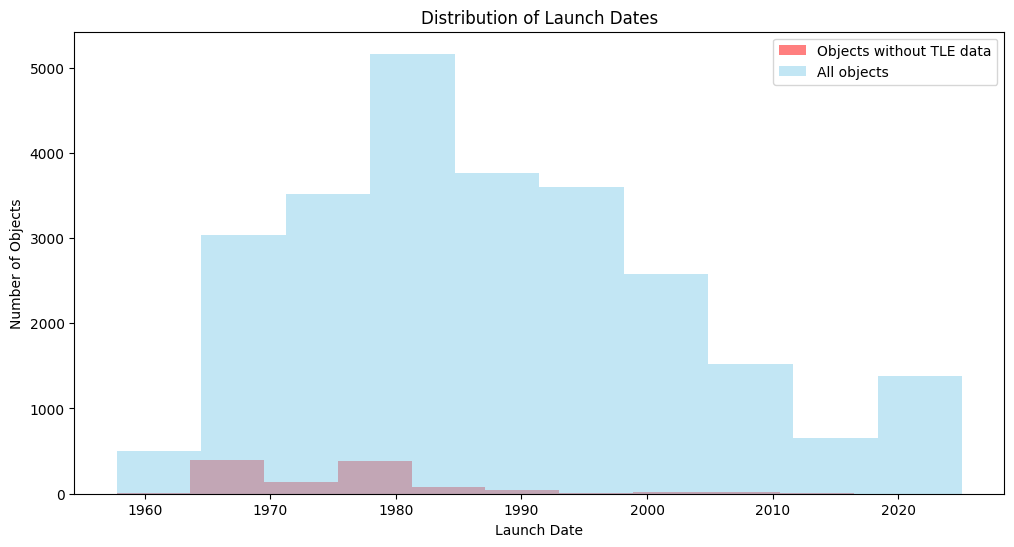

In [42]:
# display launch dates on a timeline
# convert the launch date to a datetime object
missing_OMMs_df['LAUNCH'] = pd.to_datetime(missing_OMMs_df['LAUNCH'])
combined_df['LAUNCH'] = pd.to_datetime(combined_df['LAUNCH'])

# show types of launch and decay date columns
print("Missing_TLEs_df 'LAUNCH' column datatype: ", missing_OMMs_df['LAUNCH'].dtype)
print("combined_df 'LAUNCH' column datatype: ", combined_df['LAUNCH'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['LAUNCH'], bins=10, color='red', alpha=0.5, label='Objects without TLE data')
plt.hist(combined_df['LAUNCH'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Launch Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Launch Dates')
plt.legend()
plt.show()

Missing_TLEs_df 'DECAY' column datatype:  datetime64[ns]
combined_df 'DECAY' column datatype:  datetime64[ns]


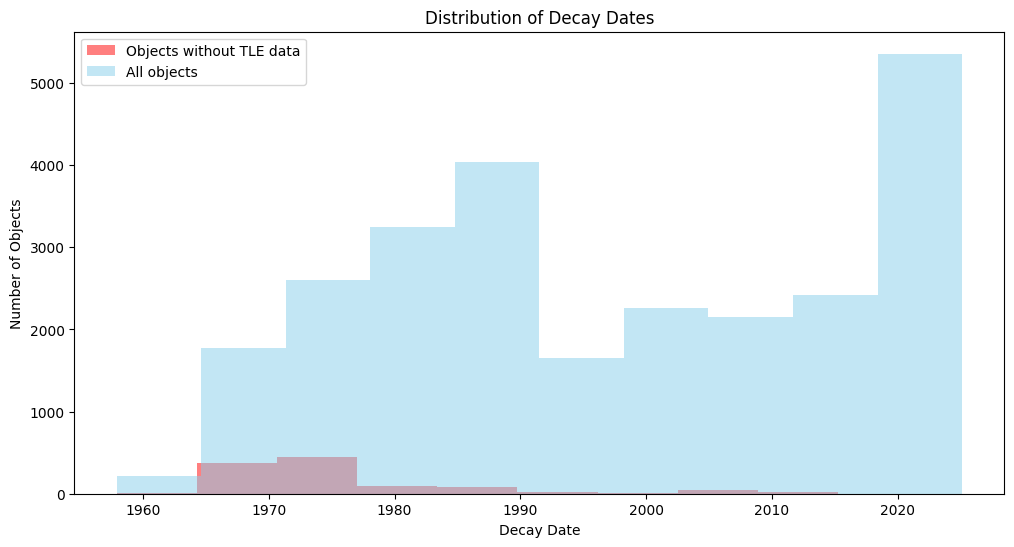

In [43]:
# display decay dates on a timeline
# convert the decay date to a datetime object
missing_OMMs_df['DECAY'] = pd.to_datetime(missing_OMMs_df['DECAY'])
combined_df['DECAY'] = pd.to_datetime(combined_df['DECAY'])

# check datatypes of decay date columns
print("Missing_TLEs_df 'DECAY' column datatype: ", missing_OMMs_df['DECAY'].dtype)
print("combined_df 'DECAY' column datatype: ", combined_df['DECAY'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_OMMs_df['DECAY'], bins=10, color='red', alpha=0.5, label='Objects without TLE data')
plt.hist(combined_df['DECAY'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Decay Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Decay Dates')
plt.legend()
plt.show()

In [44]:
# Calculate Lifetime of the Objects since the distribution of launch and decay dates is similar and suggests that maybe all objects had a too short lifetime to record TLEs
missing_OMMs_df.insert(8, 'LIFETIME', missing_OMMs_df['DECAY'] - missing_OMMs_df['LAUNCH'])
# Calculate Lifetime of all objects
combined_df.insert(8, 'LIFETIME', combined_df['DECAY'] - combined_df['LAUNCH'])

In [46]:
# review statistics of the lifetime columns
print("Lifetime statistics over all objects:")
print(combined_df['LIFETIME'].describe(), "\n")
print("Lifetime statistics over objects without OMM data:")
print(missing_OMMs_df['LIFETIME'].describe())

Lifetime statistics over all objects:
count                           25720
mean     3492 days 14:03:54.027993792
std      4752 days 02:51:45.706666176
min                   0 days 00:00:00
25%                  33 days 00:00:00
50%                 918 days 00:00:00
75%                5694 days 00:00:00
max               23115 days 00:00:00
Name: LIFETIME, dtype: object 

Lifetime statistics over objects without OMM data:
count                            1097
mean      451 days 04:34:20.893345488
std      1586 days 21:50:40.136507376
min                   0 days 00:00:00
25%                   5 days 00:00:00
50%                  14 days 00:00:00
75%                  22 days 00:00:00
max               12950 days 00:00:00
Name: LIFETIME, dtype: object


#### Objects without OMM data can be dropped unproblematically since they mostly had a relatively short lifetime and thus the explaination seems plausible that there was no chance to record OMMs.

In [ ]:
# drop objects without OMM data
combined_df.dropna(subset=['EPOCH'], inplace=True)

#### 3. Drop not needed columns: Check duplicate columns to see if they contain the same values.  If they do not, check why and which one makes more sense to drop. 

In [48]:
# compare columns with same content to check if they contain the same values
# List of column names to compare
columns_to_compare = [
    'OBJECT_TYPE', 'SITE', 'PERIOD', 'INCLINATION', 'RCS_SIZE'
]

# Initialize a dictionary to store the columns that are not equal
unequal_columns = {}

# Loop through the columns and check for inequality
for col in columns_to_compare:
    are_equal = combined_df[f'{col}_x'].equals(combined_df[f'{col}_y'])
    print(f"{col}: {are_equal}")
    if not are_equal:
        unequal_columns[f'{col}_x'] = combined_df[f'{col}_x']
        unequal_columns[f'{col}_y'] = combined_df[f'{col}_y']

# Create a DataFrame out of the unequal columns
unequal_df = pd.DataFrame(unequal_columns)

print("\nComparison of unequal columns side by side:")
unequal_df

OBJECT_TYPE: True
SITE: False
PERIOD: False
INCLINATION: False
RCS_SIZE: False

Comparison of unequal columns side by side:


,SITE_x,SITE_y,PERIOD_x,PERIOD_y,INCLINATION_x,INCLINATION_y,RCS_SIZE_x,RCS_SIZE_y
2,AFETR,AFETR,89.24,89.243,50.27,50.2674,MEDIUM,MEDIUM
3,AFETR,AFETR,87.80,87.798,48.34,48.3426,LARGE,LARGE
4,AFETR,NaN,88.38,88.378,51.25,51.2500,NaN,NaN
5,AFETR,NaN,93.59,93.607,51.29,51.2879,NaN,NaN
6,TTMTR,NaN,88.48,88.477,64.89,64.8899,NaN,NaN
...,...,...,...,...,...,...,...,...
25715,JSC,JSC,87.60,87.597,49.89,49.8914,LARGE,LARGE
25716,XSC,NaN,88.60,88.597,46.09,46.0912,LARGE,NaN
25717,RLLC,RLLC,87.73,87.734,97.51,97.5072,MEDIUM,MEDIUM
25718,AFETR,AFETR,87.80,87.802,51.62,51.6226,LARGE,LARGE


In [49]:
# check null values
# site
print("SITE_x: ", unequal_df['SITE_x'].isnull().sum())
print("SITE_y: ", unequal_df['SITE_y'].isnull().sum())
# period
print("PERIOD_x: ", unequal_df['PERIOD_x'].isnull().sum())
print("PERIOD_y: ", unequal_df['PERIOD_y'].isnull().sum())
# inclination
print("INCLINATION_x: ", unequal_df['INCLINATION_x'].isnull().sum())
print("INCLINATION_y: ", unequal_df['INCLINATION_y'].isnull().sum())
# RCS_SIZE
print("RCS_SIZE_x: ", unequal_df['RCS_SIZE_x'].isnull().sum())
print("RCS_SIZE_y: ", unequal_df['RCS_SIZE_y'].isnull().sum())


SITE_x:  0
SITE_y:  8312
PERIOD_x:  0
PERIOD_y:  0
INCLINATION_x:  0
INCLINATION_y:  0
RCS_SIZE_x:  5919
RCS_SIZE_y:  8876


In [50]:
# delete columns 
combined_df.drop(columns=[
    'OBJECT_TYPE_y', # y and y columns are the same
    'SITE_y', # x has no null values
    'PERIOD_x', # y has more decimal places
    'INCLINATION_x', # y has more decimal places 
    'RCS_SIZE_y', 'RCS_SIZE_x' # both have too many null values
    ], inplace=True)

# rename columns
combined_df.rename(columns={
    'OBJECT_TYPE_x': 'OBJECT_TYPE',
    'SITE_x': 'SITE',
    'PERIOD_y': 'PERIOD',
    'INCLINATION_y': 'INCLINATION',
    'RCS_SIZE_x': 'RCS_SIZE'
}, inplace=True)

In [51]:
# check datatypes of launch and decay columns
print("LAUNCH: ", combined_df['LAUNCH'].dtype)
print("DECAY: ", combined_df['DECAY'].dtype)
print("LAUNCH_DATE: ", combined_df['LAUNCH_DATE'].dtype)
print("DECAY_DATE: ", combined_df['DECAY_DATE'].dtype)

LAUNCH:  datetime64[ns]
DECAY:  datetime64[ns]
LAUNCH_DATE:  object
DECAY_DATE:  object


In [52]:
# convert launch and decay columns to datetime
combined_df['LAUNCH_DATE'] = pd.to_datetime(combined_df['LAUNCH'])
combined_df['DECAY_DATE'] = pd.to_datetime(combined_df['DECAY'])

In [53]:
# compare launch and decay columns 
print("Launch: ", combined_df['LAUNCH_DATE'].equals(combined_df['LAUNCH']))
print("Decay: ", combined_df['DECAY_DATE'].equals(combined_df['DECAY']))

Launch:  True
Decay:  True


In [54]:
# drop launch and decay columns
combined_df.drop(columns=['LAUNCH_DATE', 'DECAY_DATE'], inplace=True)

In [55]:
# compare Object ID and International Designator
print(combined_df['OBJECT_ID'].equals(combined_df['INTLDES']))

False


In [56]:
# show rows where Object ID and International Designator are not equal with only the relevant columns
combined_df[combined_df['OBJECT_ID'] != combined_df['INTLDES']][['OBJECT_ID', 'INTLDES']]

,OBJECT_ID,INTLDES
2331,1966-025F,1966-063F
5871,1976-124C,1976-037AB
6005,1976-124D,1976-124C
6008,1976-124E,1976-124D
6014,1976-124F,1976-124E
6015,1976-124G,1976-124F
6016,1976-124H,1976-124G
6017,1976-124J,1976-124H
6018,1976-124K,1976-124J
6019,1976-124L,1976-124K


In [57]:
# the differences seem to come from the fact that ELSET data (OBJECT_ID) gets updated more frequently and reflects fragmentations and reassignments 
# the SATCAT data (INTLDES) retains historical launch assignments 
# therefore: keep OBJECT_ID and drop INTLDES
combined_df.drop(columns=['INTLDES'], inplace=True)
# rename to INTLDES since it describes the data better
combined_df.rename(columns={'OBJECT_ID': 'INTLDES'}, inplace=True)

In [58]:
# compare SATNAME and OBJECT_NAME
print(combined_df['SATNAME'].equals(combined_df['OBJECT_NAME']))

True


In [59]:
# drop OBJECT_NAME
combined_df.drop(columns=['OBJECT_NAME'], inplace=True)

In [60]:
# change order of columns
combined_df = combined_df[['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH', 'DECAY', # information with no relevance for lifetime
                           'EPOCH', 'PERIGEE', 'APOGEE', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOAPSIS', 'PERIAPSIS', # features - OMM information
                           'LIFETIME']] # label
combined_df

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,EPOCH,PERIGEE,APOGEE,ARG_OF_PERICENTER,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,APOAPSIS,PERIAPSIS,LIFETIME
2,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1989-07-16,1989-07-14T18:51:46.968192,225.0,249.0,32.5712,16.135613,0.001834,50.2674,226.9734,327.5638,58050.0,0.003007,0.027318,0.019637,6615.232,89.243,249.232,224.963,10869 days
3,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1991-07-03,1991-07-02T11:34:12.753984,163.0,168.0,333.1829,16.401144,0.000363,48.3426,203.3369,26.9220,67681.0,0.001474,0.208109,0.000057,6543.639,87.798,167.878,163.130,11415 days
4,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-08-18,1961-08-16T14:24:53.774496,194.0,194.0,331.9473,16.293583,0.000000,51.2500,356.4892,28.0526,7590.0,0.000000,0.021256,0.000000,6572.405,88.378,194.270,194.270,492 days
5,33,1960-003C,THOR ABLESTAR DEB,DEBRIS,US,AFETR,1960-04-13,1960-07-17,1960-10-06T07:59:06.496512,285.0,615.0,196.7800,15.383434,0.024276,51.2879,136.0668,163.6100,2700.0,0.000000,0.000019,0.000000,6829.149,93.607,616.796,285.231,95 days
6,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-07-17,1960-07-16T04:00:11.150208,199.0,199.0,36.3819,16.275237,0.000000,64.8899,44.6976,323.6180,990.0,0.000000,0.032711,0.000000,6577.344,88.477,199.209,199.209,63 days
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25715,62113,2024-221C,ZQ-2E R/B,ROCKET BODY,PRC,JSC,2024-11-27,2024-12-24,2024-12-24T06:33:51.112800,127.0,184.0,178.2700,16.438900,0.004298,49.8914,275.2215,320.2910,429.0,0.000232,0.170634,0.000012,6533.612,87.597,183.558,127.396,27 days
25716,62191,2024-228B,KZ-1A R/B,ROCKET BODY,PRC,XSC,2024-12-04,2024-12-05,2024-12-05T12:05:44.031840,116.0,294.0,6.8812,16.253371,0.013499,46.0912,100.6897,42.8048,13.0,0.000480,0.338528,0.000013,6583.238,88.597,293.973,116.233,1 days
25717,62408,2024-248C,ELECTRON R/B,ROCKET BODY,US,RLLC,2024-12-21,2024-12-29,2024-12-29T17:59:05.701920,128.0,196.0,205.7092,16.413207,0.005214,97.5072,319.3027,203.0096,129.0,0.000478,0.284337,0.000002,6540.429,87.734,196.397,128.191,8 days
25718,62608,2024-200B,DRAGON CRS-31 DEB,DEBRIS,US,AFETR,2024-11-05,2025-01-29,2025-01-29T15:40:47.529696,162.0,170.0,314.7115,16.400532,0.000599,51.6226,259.7984,89.5839,247.0,0.000395,0.055156,0.000012,6543.798,87.802,169.583,161.743,85 days


In [61]:
# save to csv
combined_df.to_csv('../Data/DS_combined.csv', index=False)